In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import time
from typing import Tuple, Dict, List
import pandas as pd
import matplotlib.pyplot as plt

import torchvision.models as models

## Задание 1:

**1.1.** Используйте предобученную ResNet-18 для классификации CIFAR-10

**1.2.** Реализуйте два подхода: feature extraction (замороженный backbone) и fine-tuning

**1.3.** Сравните точность и время обучения обоих подходов

**1.4.** Проанализируйте, какой метод работает лучше и почему

### Исследование по варианту

Выполните один вариант в соответствии с номером в списке группы.

**Вариант 1. Цена разморозки.** Для обоих режимов укажите число обучаемых параметров, среднее время эпохи и итоговую accuracy на валидации. Объясните, оправдал ли выигрыш в качестве дополнительное время.

In [ ]:
resnet18 = models.resnet18(pretrained=True)
backbone = resnet18

class TransferLearningModel(nn.Module):
    def __init__(self, base_model=backbone, num_classes: int = 10, freeze_backbone: bool = True):
        super(TransferLearningModel, self).__init__()

        self.backbone = base_model
        self.freeze_backbone = freeze_backbone

        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False

        num_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Linear(num_features, num_classes)

    def forward(self, x):
        return self.backbone(x)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s]


In [ ]:
def get_data_loaders(batch_size: int = 128) -> Tuple[DataLoader, DataLoader]:
    train_transform = transforms.Compose([
        transforms.RandomHorizontalFlip(),
        transforms.RandomCrop(32, padding=4),
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465),
                             (0.2023, 0.1994, 0.2010))
    ])
    test_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465),
                             (0.2023, 0.1994, 0.2010))
    ])

    train_dataset = torchvision.datasets.CIFAR10(
        root='./data', train=True, download=True, transform=train_transform
    )
    val_dataset = torchvision.datasets.CIFAR10(
        root='./data', train=True, download=True, transform=test_transform
    )

    train_dataset.data = train_dataset.data[5000:]
    train_dataset.targets = train_dataset.targets[5000:]

    val_dataset.data = val_dataset.data[:5000]
    val_dataset.targets = val_dataset.targets[:5000]

    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, num_workers=2
    )
    val_loader = DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False, num_workers=2
    )

    return train_loader, val_loader

In [ ]:
def train_epoch(model: nn.Module,
                train_loader: DataLoader,
                criterion: nn.Module,
                optimizer: optim.Optimizer,
                device: torch.device) -> float:

    model.train()

    if model.freeze_backbone:
        model.backbone.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (inputs, targets) in enumerate(train_loader):
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()

    accuracy = 100. * correct / total
    avg_loss = running_loss / len(train_loader)

    print(f'Train Loss: {avg_loss:.4f} | Train Acc: {accuracy:.2f}%')
    return avg_loss

def evaluate(model: nn.Module,
             val_loader: DataLoader,
             criterion: nn.Module,
             device: torch.device) -> Tuple[float, float]:

    model.eval()
    val_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            val_loss += loss.item()
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

    accuracy = 100. * correct / total
    avg_loss = val_loss / len(val_loader)

    print(f'Val Loss: {avg_loss:.4f} | Val Acc: {accuracy:.2f}%')
    return avg_loss, accuracy

def train_model(model: nn.Module,
                train_loader: DataLoader,
                val_loader: DataLoader,
                epochs: int = 10,
                learning_rate: float = 0.001) -> Dict:

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)

    history = {
        'train_loss': [],
        'val_loss': [],
        'val_accuracy': []
    }

    start_time = time.time()

    for epoch in range(epochs):
        print(f'\nEpoch: {epoch + 1}/{epochs}')
        print('-' * 50)

        train_loss = train_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_accuracy = evaluate(model, val_loader, criterion, device)

        scheduler.step()

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_accuracy)

    training_time = time.time() - start_time

    history['training_time'] = training_time
    history['avg_epoch_time'] = training_time / epochs

    print(f'\nTraining completed in {training_time:.2f} seconds')

    return history

In [ ]:
def run_transfer_learning_experiment(base_model=backbone,
                                     epochs: int = 15,
                                     batch_size: int = 128,
                                     freeze_backbone: bool = True) -> Dict:

    print(f"Starting transfer learning experiment with {base_model.__class__.__name__}")
    print(f"Freeze backbone: {freeze_backbone}")

    model = TransferLearningModel(
        base_model=base_model,
        num_classes=10,
        freeze_backbone=freeze_backbone
    )

    total_params = 0
    trainable_params = 0
    for param in model.parameters():
        total_params += param.numel()
        if param.requires_grad:
            trainable_params += param.numel()

    train_loader, val_loader = get_data_loaders(batch_size=batch_size)

    history = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=epochs,
        learning_rate=0.001
    )

    history['total_params'] = total_params
    history['trainable_params'] = trainable_params

    return history

In [ ]:
try:
    print("Running single experiment with ResNet-18")
    history = run_transfer_learning_experiment(
        base_model=torchvision.models.resnet18(pretrained=True),
        epochs=15,
        batch_size=128,
        freeze_backbone=True
    )

    print("\nRunning experiment with unfrozen backbone...")
    history_unfrozen = run_transfer_learning_experiment(
        base_model=torchvision.models.resnet18(pretrained=True),
        epochs=15,
        batch_size=128,
        freeze_backbone=False
    )

except Exception as e:
    print(str(e))

Running single experiment with ResNet-18
Starting transfer learning experiment with ResNet
Freeze backbone: True


100%|██████████| 170M/170M [00:23<00:00, 7.12MB/s]


Using device: cuda

Epoch: 1/15
--------------------------------------------------
Train Loss: 1.3981 | Train Acc: 50.65%
Val Loss: 1.2205 | Val Acc: 56.14%

Epoch: 2/15
--------------------------------------------------
Train Loss: 1.2127 | Train Acc: 57.14%
Val Loss: 1.1323 | Val Acc: 59.98%

Epoch: 3/15
--------------------------------------------------
Train Loss: 1.1747 | Train Acc: 58.51%
Val Loss: 1.1016 | Val Acc: 60.82%

Epoch: 4/15
--------------------------------------------------
Train Loss: 1.1531 | Train Acc: 59.21%
Val Loss: 1.1166 | Val Acc: 60.76%

Epoch: 5/15
--------------------------------------------------
Train Loss: 1.1377 | Train Acc: 59.96%
Val Loss: 1.0927 | Val Acc: 61.22%

Epoch: 6/15
--------------------------------------------------
Train Loss: 1.1226 | Train Acc: 60.41%
Val Loss: 1.0693 | Val Acc: 61.76%

Epoch: 7/15
--------------------------------------------------
Train Loss: 1.1158 | Train Acc: 60.44%
Val Loss: 1.0890 | Val Acc: 61.64%

Epoch: 8/15
--

In [ ]:
print("Feature Extraction:")
print(f"Обучаемые параметры: {history['trainable_params']}")
print(f"Среднее время эпохи: {history['avg_epoch_time']:.2f} с")
print(f"Общее время обучения: {history['training_time']:.2f} с")
print(f"Accuracy: {history['val_accuracy'][-1]:.2f}%")

print("\nFine-Tuning:")
print(f"Обучаемые параметры: {history_unfrozen['trainable_params']}")
print(f"Среднее время эпохи: {history_unfrozen['avg_epoch_time']:.2f} с")
print(f"Общее время обучения: {history_unfrozen['training_time']:.2f} с")
print(f"Accuracy: {history_unfrozen['val_accuracy'][-1]:.2f}%")

Feature Extraction:
Обучаемые параметры: 5130
Среднее время эпохи: 17.89 с
Общее время обучения: 268.30 с
Accuracy: 62.22%

Fine-Tuning:
Обучаемые параметры: 11181642
Среднее время эпохи: 20.01 с
Общее время обучения: 300.22 с
Accuracy: 87.56%


Метод Fine-Tuning показал лучший результат, т.к. у него больше точность на валидации. При Fine-Tuning обучаются все слои нейросети, позволяя адаптировать извлекаемые признаки под CIFAR-10, а при Feature Extraction обучается только последний классификационный слой

Дополнительное время обучения оправдано, т.к. Fine-Tuning повысил точность при небольшом увеличении времени

## Задание 2: Сравнение архитектур моделей

**2.1.** Возьмите три модели из своего варианта.

**2.2.** Примените перенос обучения на CIFAR-10 для каждой архитектуры

**2.3.** Сведите в таблицу валидационную accuracy, общее и обучаемое число параметров и среднее время эпохи.

**2.4.** Объясните, какую модель выбрали бы при ограниченном времени на обучение.

### Исследование по варианту

Выполните один вариант в соответствии с номером в списке группы.

**Вариант 1. Глубина ResNet.** Сравните ResNet-18, ResNet-34 и ResNet-50. По результатам объясните, что дала более глубокая модель.

In [ ]:
print("Running experiment with ResNet-34")
history34 = run_transfer_learning_experiment(
    base_model=torchvision.models.resnet34(pretrained=True),
    epochs=15,
    batch_size=128,
    freeze_backbone=False
)

print("\nRunning experiment with ResNet-50")
history50 = run_transfer_learning_experiment(
    base_model=torchvision.models.resnet50(pretrained=True),
    epochs=15,
    batch_size=128,
    freeze_backbone=False
)

Running experiment with ResNet-34


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet34_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet34_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 208MB/s]


Starting transfer learning experiment with ResNet
Freeze backbone: False
Using device: cuda

Epoch: 1/15
--------------------------------------------------
Train Loss: 1.0455 | Train Acc: 63.54%
Val Loss: 0.7904 | Val Acc: 73.96%

Epoch: 2/15
--------------------------------------------------
Train Loss: 0.7438 | Train Acc: 74.52%
Val Loss: 0.7812 | Val Acc: 73.68%

Epoch: 3/15
--------------------------------------------------
Train Loss: 0.6632 | Train Acc: 77.26%
Val Loss: 0.5534 | Val Acc: 80.46%

Epoch: 4/15
--------------------------------------------------
Train Loss: 0.6188 | Train Acc: 78.98%
Val Loss: 0.5866 | Val Acc: 79.92%

Epoch: 5/15
--------------------------------------------------
Train Loss: 0.5631 | Train Acc: 80.67%
Val Loss: 0.5244 | Val Acc: 82.20%

Epoch: 6/15
--------------------------------------------------
Train Loss: 0.5208 | Train Acc: 82.07%
Val Loss: 0.5676 | Val Acc: 80.32%

Epoch: 7/15
--------------------------------------------------
Train Loss: 0.50

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 185MB/s]


Starting transfer learning experiment with ResNet
Freeze backbone: False
Using device: cuda

Epoch: 1/15
--------------------------------------------------
Train Loss: 1.0230 | Train Acc: 65.06%
Val Loss: 0.8919 | Val Acc: 70.68%

Epoch: 2/15
--------------------------------------------------
Train Loss: 0.7695 | Train Acc: 74.14%
Val Loss: 0.7223 | Val Acc: 75.38%

Epoch: 3/15
--------------------------------------------------
Train Loss: 0.6392 | Train Acc: 78.36%
Val Loss: 0.6042 | Val Acc: 79.58%

Epoch: 4/15
--------------------------------------------------
Train Loss: 0.7679 | Train Acc: 73.80%
Val Loss: 0.6291 | Val Acc: 78.66%

Epoch: 5/15
--------------------------------------------------
Train Loss: 0.5970 | Train Acc: 79.65%
Val Loss: 0.4868 | Val Acc: 83.28%

Epoch: 6/15
--------------------------------------------------
Train Loss: 0.5379 | Train Acc: 81.84%
Val Loss: 0.4790 | Val Acc: 83.72%

Epoch: 7/15
--------------------------------------------------
Train Loss: 0.51

In [ ]:
results = pd.DataFrame({
    'Модель': ['ResNet-18', 'ResNet-34', 'ResNet-50'],
    'Val Accuracy (%)': [
        history_unfrozen['val_accuracy'][-1],
        history34['val_accuracy'][-1],
        history50['val_accuracy'][-1]
    ],
    'Общее число параметров': [
        history_unfrozen['total_params'],
        history34['total_params'],
        history50['total_params']
    ],
    'Обучаемые параметры': [
        history_unfrozen['trainable_params'],
        history34['trainable_params'],
        history50['trainable_params']
    ],
    'Среднее время эпохи': [
        history_unfrozen['avg_epoch_time'],
        history34['avg_epoch_time'],
        history50['avg_epoch_time']
    ]
})

display(results.round(2))

,Модель,Val Accuracy (%),Общее число параметров,Обучаемые параметры,Среднее время эпохи
0,ResNet-18,87.56,11181642,11181642,20.01
1,ResNet-34,87.72,21289802,21289802,24.60
2,ResNet-50,89.04,23528522,23528522,38.69


При ограниченном времени обучения целесообразно выбрать ResNet-18, поскольку она обеспечивает точность 87,56% при среднем времени эпохи 20,01 секунды. ResNet-50 повышает точность лишь немного процентного пункта, но требует почти в 2 раза больше времени на каждую эпоху

Увеличение глубины ResNet привело к повышению точности у ResNet-34 и у ResNet-50 в сравнении с ResNet-18. Это благодаря способности более глубоких архитектур извлекать более сложные признаки изображений. Вместе с ростом точности увеличилось число параметров и время обучения

## Задание 3: Влияние размера обучающей выборки

**3.1.** dataset CIFAR-10

**3.2.** Создайте три подвыборки по долям из своего варианта. Считайте проценты от обучающей части после выделения валидации.

**3.3.** Для каждого размера обучите модель с переносом обучения (Таблица сравнения метрик)

**3.4.** Постройте график зависимости точности от размера выборки

**3.5.** Проанализируйте, как меняется точность при добавлении данных.

### Исследование по варианту

Выполните один вариант в соответствии с номером в списке группы.

**Вариант 1. Мало данных.** Сравните 1%, 5% и 10%. Укажите, насколько меняется точность при первых добавлениях данных.

In [ ]:
percentages = [1, 5, 10]
histories3 = []
counts = []

for percent in percentages:
    train_loader, val_loader = get_data_loaders(batch_size=128)

    count = len(train_loader.dataset) * percent // 100

    train_loader.dataset.data = train_loader.dataset.data[:count]
    train_loader.dataset.targets = train_loader.dataset.targets[:count]

    counts.append(count)

    print(f"\nTraining on {percent}% of data ({count} images)")

    model = TransferLearningModel(
        base_model=torchvision.models.resnet18(pretrained=True),
        num_classes=10,
        freeze_backbone=False
    )

    history3 = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=15,
        learning_rate=0.001
    )

    histories3.append(history3)


Training on 1% of data (450 images)
Using device: cuda


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



Epoch: 1/15
--------------------------------------------------
Train Loss: 2.3620 | Train Acc: 16.22%
Val Loss: 2.0866 | Val Acc: 21.44%

Epoch: 2/15
--------------------------------------------------
Train Loss: 1.8212 | Train Acc: 35.33%
Val Loss: 1.9973 | Val Acc: 28.98%

Epoch: 3/15
--------------------------------------------------
Train Loss: 1.6195 | Train Acc: 45.78%
Val Loss: 1.8660 | Val Acc: 33.72%

Epoch: 4/15
--------------------------------------------------
Train Loss: 1.3438 | Train Acc: 53.33%
Val Loss: 1.8729 | Val Acc: 34.04%

Epoch: 5/15
--------------------------------------------------
Train Loss: 1.2229 | Train Acc: 56.44%
Val Loss: 2.0691 | Val Acc: 32.72%

Epoch: 6/15
--------------------------------------------------
Train Loss: 1.0143 | Train Acc: 65.33%
Val Loss: 2.3037 | Val Acc: 33.00%

Epoch: 7/15
--------------------------------------------------
Train Loss: 0.8653 | Train Acc: 71.78%
Val Loss: 2.3747 | Val Acc: 36.82%

Epoch: 8/15
---------------------

In [ ]:
results3 = pd.DataFrame({
    'Доля': percentages,
    'Количество изображений': counts,
    'Val Accuracy': [
        histories3[0]['val_accuracy'][-1],
        histories3[1]['val_accuracy'][-1],
        histories3[2]['val_accuracy'][-1]
    ],
    'Val Loss': [
        histories3[0]['val_loss'][-1],
        histories3[1]['val_loss'][-1],
        histories3[2]['val_loss'][-1]
    ],
    'Среднее время эпохи': [
        histories3[0]['avg_epoch_time'],
        histories3[1]['avg_epoch_time'],
        histories3[2]['avg_epoch_time']
    ]
})
display(results3.round(2))

,Доля,Количество изображений,Val Accuracy,Val Loss,Среднее время эпохи
0,1,450,50.46,1.80,1.74
1,5,2250,71.96,0.95,2.87
2,10,4500,77.12,0.71,3.90


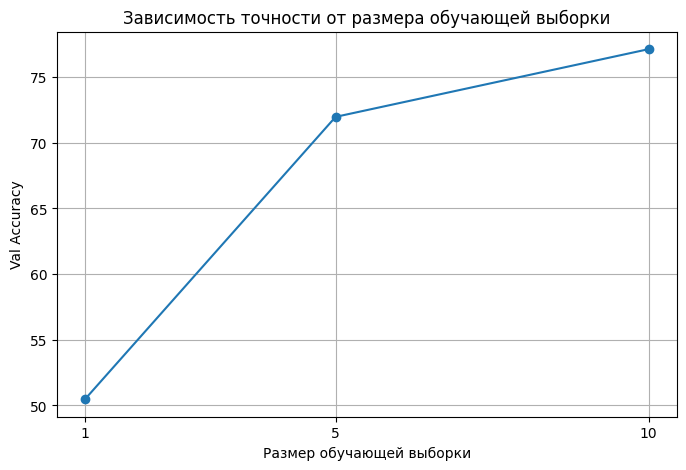

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(results3['Доля'], results3['Val Accuracy'], marker='o')
plt.xlabel('Размер обучающей выборки')
plt.ylabel('Val Accuracy')
plt.title('Зависимость точности от размера обучающей выборки')
plt.xticks(percentages)
plt.grid(True)
plt.show()

In [ ]:
accuracy_1 = histories3[0]['val_accuracy'][-1]
accuracy_5 = histories3[1]['val_accuracy'][-1]
accuracy_10 = histories3[2]['val_accuracy'][-1]

print(f"Прирост точности от 1% до 5%: {accuracy_5 - accuracy_1:.2f}")
print(f"Прирост точности от 5% до 10%: {accuracy_10 - accuracy_5:.2f}")
print(f"Общий прирост от 1% до 10%: {accuracy_10 - accuracy_1:.2f}")

Прирост точности от 1% до 5%: 21.50
Прирост точности от 5% до 10%: 5.16
Общий прирост от 1% до 10%: 26.66


При увеличении обучающей выборки с 1% до 5% и 10% точность на валидации выросла с 50,46% до 71,96% и 77,12% соответственно. Увеличение количества обучающих данных улучшает точность классификации, но прирост постепенно замедляется

При увеличении выборки с 1% до 5% точность повысилась на 21,50, а с 5% до 10% — на 5,16. Наибольший прирост точности наблюдается при первом увеличении объёма обучающих данных


## Задание 4: Поэтапное размораживание слоев
- 4.1. Реализуйте стратегию постепенного размораживания слоев ResNet-18.
- 4.2. Начните с замороженного backbone, обучайте только классификатор.
- 4.3. Разморозьте и дообучите последний блок слоев.
- 4.4. Наконец, разморозьте всю модель.
- 4.5. Сравните с одноэтапным fine-tuning.

Визуализация процесса обучения для каждого этапа.
Сравнение стабильности обучения и конечной точности.

In [ ]:
def progressive_unfreezing(model, train_loader, val_loader, epochs=20):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)

    history = {
        'train_loss': [],
        'val_loss': [],
        'val_accuracy': []
    }

    for epoch in range(epochs):
        if epoch == 0:
            for param in model.parameters():
                param.requires_grad = False
            for param in model.backbone.fc.parameters():
                param.requires_grad = True
            model.freeze_backbone = True
            print("\nStage 1: Classifier")
        elif epoch == 5:
            for param in model.backbone.layer4.parameters():
                param.requires_grad = True
            print("\nStage 2: Layer4 + Classifier")
        elif epoch == 15:
            for param in model.parameters():
                param.requires_grad = True
            model.freeze_backbone = False
            print("\nStage 3: Full Model")

        print(f'\nEpoch: {epoch + 1}/{epochs}')
        print('-' * 50)

        train_loss = train_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_accuracy = evaluate(model, val_loader, criterion, device)
        scheduler.step()

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_accuracy)

    return history

In [ ]:
train_loader, val_loader = get_data_loaders(batch_size=128)

print("Progressive Unfreezing")
model4 = TransferLearningModel(
    base_model=torchvision.models.resnet18(pretrained=True),
    num_classes=10,
    freeze_backbone=True
)

history4 = progressive_unfreezing(
    model=model4,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=20
)

print("\nFine-Tuning")
model4_full = TransferLearningModel(
    base_model=torchvision.models.resnet18(pretrained=True),
    num_classes=10,
    freeze_backbone=False
)

history4_full = train_model(
    model=model4_full,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=20,
    learning_rate=0.001
)

Progressive Unfreezing
Using device: cuda

Stage 1: Classifier

Epoch: 1/20
--------------------------------------------------


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Train Loss: 1.4017 | Train Acc: 50.53%
Val Loss: 1.2038 | Val Acc: 57.58%

Epoch: 2/20
--------------------------------------------------
Train Loss: 1.2154 | Train Acc: 57.04%
Val Loss: 1.1382 | Val Acc: 60.54%

Epoch: 3/20
--------------------------------------------------
Train Loss: 1.1699 | Train Acc: 58.86%
Val Loss: 1.1090 | Val Acc: 60.50%

Epoch: 4/20
--------------------------------------------------
Train Loss: 1.1514 | Train Acc: 59.34%
Val Loss: 1.1014 | Val Acc: 60.96%

Epoch: 5/20
--------------------------------------------------
Train Loss: 1.1369 | Train Acc: 59.78%
Val Loss: 1.0735 | Val Acc: 62.02%

Stage 2: Layer4 + Classifier

Epoch: 6/20
--------------------------------------------------
Train Loss: 1.1705 | Train Acc: 59.06%
Val Loss: 0.8698 | Val Acc: 69.12%

Epoch: 7/20
--------------------------------------------------
Train Loss: 0.9620 | Train Acc: 65.74%
Val Loss: 0.8189 | Val Acc: 71.34%

Epoch: 8/20
--------------------------------------------------
Trai

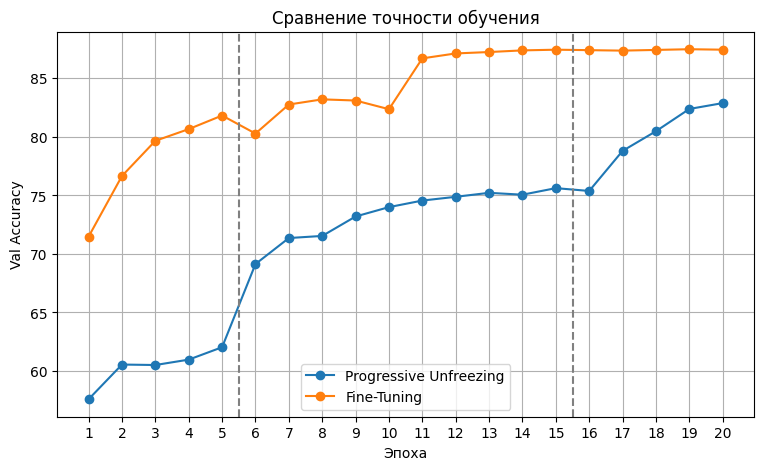

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(range(1, 21), history4['val_accuracy'], marker='o', label='Progressive Unfreezing')
plt.plot(range(1, 21), history4_full['val_accuracy'], marker='o', label='Fine-Tuning')

plt.axvline(x=5.5, color='gray', linestyle='--')
plt.axvline(x=15.5, color='gray', linestyle='--')

plt.xlabel('Эпоха')
plt.ylabel('Val Accuracy')
plt.title('Сравнение точности обучения')
plt.xticks(range(1, 21))
plt.legend()
plt.grid(True)
plt.show()

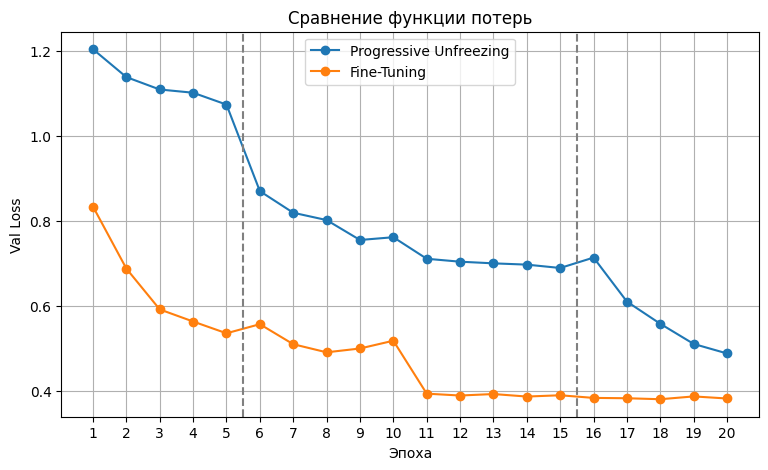

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(range(1, 21), history4['val_loss'], marker='o', label='Progressive Unfreezing')
plt.plot(range(1, 21), history4_full['val_loss'], marker='o', label='Fine-Tuning')

plt.axvline(x=5.5, color='gray', linestyle='--')
plt.axvline(x=15.5, color='gray', linestyle='--')

plt.xlabel('Эпоха')
plt.ylabel('Val Loss')
plt.title('Сравнение функции потерь')
plt.xticks(range(1, 21))
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
results4 = pd.DataFrame({
    'Этап': ['Классификатор', 'Layer4 + Classifier', 'Вся модель'],
    'Эпоха': [5, 15, 20],
    'Progressive Unfreezing': [
        history4['val_accuracy'][4],
        history4['val_accuracy'][14],
        history4['val_accuracy'][19]
    ],
    'Fine-Tuning': [
        history4_full['val_accuracy'][4],
        history4_full['val_accuracy'][14],
        history4_full['val_accuracy'][19]
    ]
})
display(results4.round(2))

print(f"Разница итоговой точности: {history4['val_accuracy'][-1] - history4_full['val_accuracy'][-1]:.2f}")

,Этап,Эпоха,Progressive Unfreezing,Fine-Tuning
0,Классификатор,5,62.02,81.80
1,Layer4 + Classifier,15,75.60,87.42
2,Вся модель,20,82.86,87.42


Разница итоговой точности: -4.56


Обычный Fine-Tuning показал более стабильное обучение на заключительных эпохах и более высокую итоговую точность. В данном эксперименте поэтапное размораживание не обеспечило преимущества перед обычным Fine-Tuning

## Задание 5: Адаптация под другую задачу - бинарная классификация

- 5.1. Используйте Food101 (https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.Food101.html#torchvision.datasets.Food101)
- 5.2. Настройте предобученную модель для классификации Food101
- 5.3. Экспериментируйте с различными функциями активации на выходе
- 5.4. Сравните разные стратегии инициализации последнего слоя

### Дополнительное задание по варианту

Выполните один вариант по номеру в списке группы. Для выбранной пары классов посчитайте долю верных ответов отдельно по каждому классу на отложенных данных. Приведите по одному примеру ошибки для каждого класса, если такие ошибки есть. Объясните, какой класс модель распознаёт хуже или почему по вашим результатам нельзя выделить такой класс.

**Вариант 1. Пицца или бургер.** Возьмите классы `pizza` и `hamburger`.

In [ ]:
def get_food_loaders(batch_size=32):
    train_transform = transforms.Compose([
        transforms.Resize((128, 128)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize((0.485, 0.456, 0.406),
                             (0.229, 0.224, 0.225))
    ])
    test_transform = transforms.Compose([
        transforms.Resize((128, 128)),
        transforms.ToTensor(),
        transforms.Normalize((0.485, 0.456, 0.406),
                             (0.229, 0.224, 0.225))
    ])

    train_dataset = torchvision.datasets.Food101(
        root='./data', split='train', download=True, transform=train_transform
    )

    train_dataset, val_dataset = torch.utils.data.random_split(
        train_dataset, [60600, 15150]
    )

    val_dataset.dataset = torchvision.datasets.Food101(
        root='./data', split='train', download=False, transform=test_transform
    )
    test_dataset = torchvision.datasets.Food101(
        root='./data', split='test', download=False, transform=test_transform
    )

    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, num_workers=2
    )
    val_loader = DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False, num_workers=2
    )

    return train_loader, val_loader, test_dataset

In [ ]:
def sigmoid_loss(outputs, targets):
    targets = nn.functional.one_hot(targets, num_classes=101).float()
    return nn.functional.binary_cross_entropy_with_logits(outputs, targets)


def train_food_model(model, train_loader, val_loader, activation, epochs=5):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    model = model.to(device)

    if activation == 'Softmax':
        criterion = nn.CrossEntropyLoss()
    else:
        criterion = sigmoid_loss

    optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

    history = {
        'train_loss': [],
        'val_loss': [],
        'val_accuracy': []
    }

    for epoch in range(epochs):
        print(f'\nEpoch: {epoch + 1}/{epochs}')
        print('-' * 50)

        train_loss = train_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_accuracy = evaluate(model, val_loader, criterion, device)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_accuracy)

    return history

In [ ]:
train_loader, val_loader, test_dataset = get_food_loaders(batch_size=32)

results5 = []
best_accuracy = -1

for activation in ['Softmax', 'Sigmoid']:
    for initialization in ['Standard', 'Zeros']:
        print(f"\nActivation: {activation}, Initialization: {initialization}")

        model = TransferLearningModel(
            base_model=torchvision.models.resnet18(pretrained=True),
            num_classes=101,
            freeze_backbone=True
        )

        if initialization == 'Zeros':
            nn.init.zeros_(model.backbone.fc.weight)
            nn.init.zeros_(model.backbone.fc.bias)

        history5 = train_food_model(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            activation=activation,
            epochs=5
        )

        accuracy = history5['val_accuracy'][-1]

        results5.append({
            'Активация': activation,
            'Инициализация': initialization,
            'Val Accuracy': accuracy
        })

        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_model = model
            best_activation = activation
            best_initialization = initialization

results5_df = pd.DataFrame(results5)
display(results5_df.round(2))


Activation: Softmax, Initialization: Standard
Using device: cuda

Epoch: 1/5
--------------------------------------------------
Train Loss: 2.7726 | Train Acc: 34.23%
Val Loss: 2.5294 | Val Acc: 39.03%

Epoch: 2/5
--------------------------------------------------
Train Loss: 2.3751 | Train Acc: 41.91%
Val Loss: 2.5232 | Val Acc: 39.80%

Epoch: 3/5
--------------------------------------------------
Train Loss: 2.2926 | Train Acc: 43.74%
Val Loss: 2.4907 | Val Acc: 40.86%

Epoch: 4/5
--------------------------------------------------
Train Loss: 2.2399 | Train Acc: 45.16%
Val Loss: 2.5336 | Val Acc: 40.30%

Epoch: 5/5
--------------------------------------------------
Train Loss: 2.2054 | Train Acc: 46.03%
Val Loss: 2.4688 | Val Acc: 41.62%

Activation: Softmax, Initialization: Zeros
Using device: cuda

Epoch: 1/5
--------------------------------------------------
Train Loss: 2.7048 | Train Acc: 35.27%
Val Loss: 2.4723 | Val Acc: 39.85%

Epoch: 2/5
-------------------------------------

,Активация,Инициализация,Val Accuracy
0,Softmax,Standard,41.62
1,Softmax,Zeros,39.87
2,Sigmoid,Standard,39.06
3,Sigmoid,Zeros,38.38


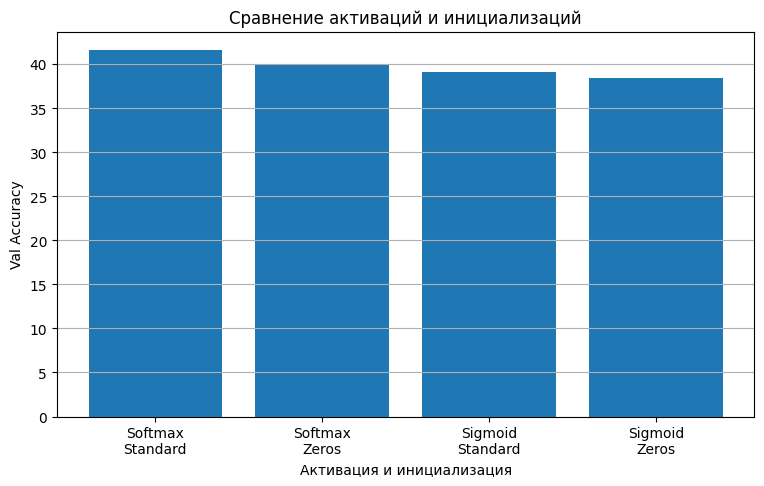

Лучшая активация: Softmax
Лучшая инициализация: Standard
Лучшая точность: 41.62%


In [ ]:
labels = [
    f"{row['Активация']}\n{row['Инициализация']}"
    for _, row in results5_df.iterrows()
]

plt.figure(figsize=(9, 5))
plt.bar(labels, results5_df['Val Accuracy'])
plt.xlabel('Активация и инициализация')
plt.ylabel('Val Accuracy')
plt.title('Сравнение активаций и инициализаций')
plt.grid(axis='y')
plt.show()

print(f"Лучшая активация: {best_activation}")
print(f"Лучшая инициализация: {best_initialization}")
print(f"Лучшая точность: {best_accuracy:.2f}%")

In [ ]:
pizza_id = test_dataset.class_to_idx['pizza']
hamburger_id = test_dataset.class_to_idx['hamburger']

test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False, num_workers=2
)

device = next(best_model.parameters()).device
best_model.eval()

correct = {pizza_id: 0, hamburger_id: 0}
total = {pizza_id: 0, hamburger_id: 0}
errors = {}

with torch.no_grad():
    for inputs, targets in test_loader:
        mask = (targets == pizza_id) | (targets == hamburger_id)

        if not mask.any():
            continue

        inputs = inputs[mask]
        targets = targets[mask]

        outputs = best_model(inputs.to(device))
        predicted = outputs.argmax(1).cpu()

        for i in range(len(targets)):
            label = targets[i].item()
            total[label] += 1

            if predicted[i].item() == label:
                correct[label] += 1
            elif label not in errors:
                errors[label] = (inputs[i].cpu(), predicted[i].item())

print(f"Лучшая модель: {best_activation}, {best_initialization}")

for label in [pizza_id, hamburger_id]:
    accuracy = 100 * correct[label] / total[label]
    print(f"{test_dataset.classes[label]}: {correct[label]}/{total[label]} ({accuracy:.2f}%)")

pizza_accuracy = 100 * correct[pizza_id] / total[pizza_id]
hamburger_accuracy = 100 * correct[hamburger_id] / total[hamburger_id]

if pizza_accuracy > hamburger_accuracy:
    print('Хуже распознаётся hamburger')
elif hamburger_accuracy > pizza_accuracy:
    print('Хуже распознаётся pizza')
else:
    print('Точность распознавания классов одинаковая')

Лучшая модель: Softmax, Standard
pizza: 168/250 (67.20%)
hamburger: 72/250 (28.80%)
Хуже распознаётся hamburger


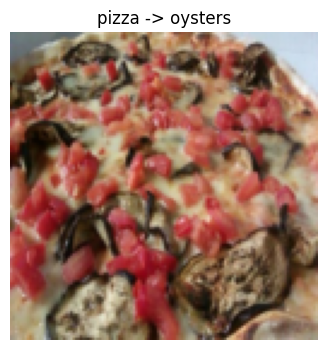

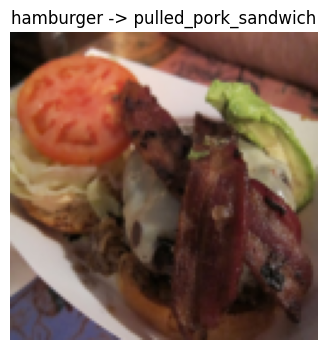

In [ ]:
for label in [pizza_id, hamburger_id]:
    if label in errors:
        image, predicted = errors[label]

        image = image.permute(1, 2, 0)
        image = image * torch.tensor([0.229, 0.224, 0.225])
        image = image + torch.tensor([0.485, 0.456, 0.406])

        plt.figure(figsize=(4, 4))
        plt.imshow(image.clamp(0, 1))
        plt.title(
            f'{test_dataset.classes[label]} -> '
            f'{test_dataset.classes[predicted]}'
        )
        plt.axis('off')
        plt.show()

Модель хуже распознаёт класс hamburger. Разность в точности классов pizza и hamburger составляет 38,40, т.к. было больше ошибок при классификации бургеров. Возможная причина - внешнее сходство бургеров с другими блюдами из Food101, и модель чаще путает их с другими классами